# 03 - Results

Results of final evaluation runs, read back from MLflow. All final runs use same code and same sampled pages (seed 0), hence numbers are directly comparable.

Sections:

1. Session context - what borrowing from same-session photos buys
2. Template against LLM writer
3. Validator fix for scene words - before and after
4. Hand review against LLM judge
5. Failure cases
6. Repetition when a folder is laid out as a book

In [18]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
mlflow.set_tracking_uri(os.environ.get("MLFLOW_TRACKING_URI", "sqlite:///mlflow.db"))

# Final runs start from here
FINAL_FROM = pd.Timestamp("2026-10-31 18:39", tz="UTC")

# LLM run rated manually before scene word fix
REVIEW_RUN = "181aa8962a0746869bfef67eaac47662"

TEMPLATE, LLM, PAGE_ONLY = "#2a78d6", "#eb6834", "#9a9a9a"
LABELLED = ["day-at-beach", "garden-birthday-party", "skiing-holiday"]

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
        "figure.dpi": 110,
    }
)
pd.set_option("display.precision", 3)

## Runs

Every eval run is in MLflow with settings, metrics and per-page outputs. `pick` takes latest final run for a given set of settings.

In [19]:
runs = mlflow.search_runs(experiment_names=["caption-evaluation"], order_by=["start_time DESC"])
runs["writer"] = runs["params.writer"].str.split(":").str[0]
runs["judged"] = runs["params.judge"] != "off"


def pick(
    writer: str, context: bool = True, mode: str = "random", judged: bool = False
) -> pd.Series:
    match = runs[
        (runs["writer"] == writer)
        & (runs["params.use_context"] == str(context))
        & (runs["params.mode"] == mode)
        & (runs["judged"] == judged)
        & (runs["start_time"] >= FINAL_FROM)
    ]
    return match.iloc[0]


def table(selected: dict[str, pd.Series], keys: list[str], prefix: str = "all") -> pd.DataFrame:
    return pd.DataFrame(
        {
            name: {k: run.get(f"metrics.{prefix}/{k}") for k in keys}
            for name, run in selected.items()
        }
    ).T


final = {
    "template, page only": pick("template", context=False),
    "template, context": pick("template"),
    "template, context, consecutive": pick("template", mode="consecutive"),
    "llm, page only": pick("llm", context=False),
    "llm, context": pick("llm"),
    "llm, context, consecutive": pick("llm", mode="consecutive"),
    "template, judged": pick("template", judged=True),
    "llm, judged": pick("llm", judged=True),
}
pd.DataFrame(
    {
        name: {
            "run": run["run_id"][:8],
            "started": run["start_time"].strftime("%H:%M"),
            "pages": int(run["metrics.all/pages"]),
        }
        for name, run in final.items()
    }
).T

,run,started,pages
"template, page only",a3fb98c5,18:40,360
"template, context",01350a1f,18:40,360
"template, context, consecutive",e769769f,18:41,360
"llm, page only",2359fd64,18:41,360
"llm, context",7d7513c6,18:40,360
"llm, context, consecutive",c27b91f7,18:41,360
"template, judged",c4a800cb,18:48,360
"llm, judged",96bc0153,18:55,360


Each run captions 90 pages per folder after near-duplicate removal. Four folders, hence 360 pages per run. Three folders have an expected occasion. Grandkids folder has none, so it counts towards grounding and variety but not accuracy.

## 1. Session context

Pages captioned on their own photos only, against pages that may borrow occasion from other photos taken within 6 hours and 25 km.

In [20]:
keys = ["accuracy", "wrong", "abstained", "occasion_borrowed", "years_grounded"]
table(
    {
        k: final[k]
        for k in ["template, page only", "template, context", "template, context, consecutive"]
    },
    keys,
)

,accuracy,wrong,abstained,occasion_borrowed,years_grounded
"template, page only",0.585,0.022,0.393,0.000,1.0
"template, context",0.985,0.004,0.011,0.372,1.0
"template, context, consecutive",0.982,0.004,0.015,0.339,1.0


Context lifts accuracy from 0.59 to 0.98, mainly by cutting abstentions from 39% to about 1%. Wrong occasions also drop, from 2.2% to 0.4%, since borrowing only happens when setting is compatible and nothing on the page blocks it. Consecutive pages - closer to a real book - behave the same as random ones. Years are grounded in EXIF on every page. Writers share the same facts, hence LLM rows (section 2) have identical accuracy.

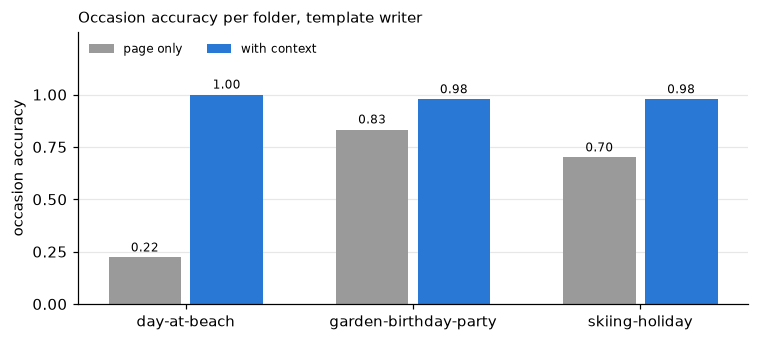

In [21]:
page_only, context = final["template, page only"], final["template, context"]
acc = pd.DataFrame(
    {
        "page only": [page_only[f"metrics.{f}/accuracy"] for f in LABELLED],
        "with context": [context[f"metrics.{f}/accuracy"] for f in LABELLED],
    },
    index=LABELLED,
)

fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.36
x = range(len(acc))
for offset, (name, colour) in zip(
    (-width / 2, width / 2), [("page only", PAGE_ONLY), ("with context", TEMPLATE)]
):
    bars = ax.bar([i + offset for i in x], acc[name], width - 0.04, color=colour, label=name)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
ax.set_xticks(list(x), acc.index)
ax.set_ylim(0, 1.3)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.set_ylabel("occasion accuracy")
ax.set_title("Occasion accuracy per folder, template writer", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left", ncols=2, fontsize=8)
plt.tight_layout()

Gain largest for the beach folder (0.22 to 1.00), where most photos are close ups of people with little beach in frame.
Party and ski pages carry more of their occasion on their own, yet still gain.

## 2. Template against LLM writer

Same facts, two writers. Judge and CLIP scores come from the judged runs, variety from the sweep.

In [22]:
keys = [
    "accuracy",
    "writer_rejected",
    "distinct_captions",
    "mean_length",
    "judge_faithful",
    "judge_specific",
    "judge_natural",
    "judge_unsupported",
    "clip",
    "clip_gain",
]
table({"template": final["template, judged"], "llm": final["llm, judged"]}, keys)

,accuracy,writer_rejected,distinct_captions,mean_length,judge_faithful,judge_specific,judge_natural,judge_unsupported,clip,clip_gain
template,0.985,0.000,0.039,41.53,4.803,5.0,4.947,0.042,0.257,0.000
llm,0.985,0.075,0.153,35.67,4.769,5.0,4.978,0.075,0.249,-0.009


In [23]:
keys = ["distinct_captions", "writer_rejected"]
table(
    {
        k: final[k]
        for k in [
            "template, context",
            "llm, context",
            "template, context, consecutive",
            "llm, context, consecutive",
        ]
    },
    keys,
)

,distinct_captions,writer_rejected
"template, context",0.039,0.000
"llm, context",0.131,0.064
"template, context, consecutive",0.033,0.000
"llm, context, consecutive",0.125,0.075


LLM gives approx 4 times the variety of the template, at almost equal faithfulness by the judge (4.77 against 4.80). Validator rejects about 7.5% of LLM captions, which fall back to the template. CLIP sees no real difference and gain is within noise, as expected for captions built from the same facts. LLM variety moves a little between runs since sampling isn't deterministic.

In [24]:
reasons_path = mlflow.artifacts.download_artifacts(
    run_id=final["llm, judged"]["run_id"], artifact_path="rejection_reasons.json"
)
pd.Series(json.loads(Path(reasons_path).read_text()), name="pages").head(8).to_frame()

,pages
"<word> describes the scene, which the facts don't",27


## 3. Validator fix for scene words

First version of the validator only checked capitalised words, hence "in the snow" and "in the dark" passed. Fix added season, weather, time of day, rooms and scenery, each allowed only when facts or labels support it. Both runs below are LLM runs with the judge, on 10 pages per size, before and after the fix.

In [25]:
before = runs[runs["run_id"] == REVIEW_RUN].iloc[0]
after = runs[
    (runs["writer"] == "llm")
    & runs["judged"]
    & (runs["params.pages_per_size"] == "10")
    & (runs["start_time"] > before["start_time"])
    & (runs["start_time"] < FINAL_FROM)
].iloc[0]
keys = ["writer_rejected", "distinct_captions", "judge_faithful", "judge_unsupported"]
table({"before fix": before, "after fix": after}, keys)

,writer_rejected,distinct_captions,judge_faithful,judge_unsupported
before fix,0.00,0.342,4.642,0.133
after fix,0.05,0.250,4.750,0.075


Fix raised judge faithfulness from 4.64 to 4.75 and rejected about 5% of LLM captions. Cost is some variety, since rejected captions become template captions.

## 4. Hand review against LLM judge

32 pages from the pre-fix run, sampled evenly across folders, rated 1 to 5 for faithfulness (is everything true of the photos) and naturalness (would you print it in your own book). Same pages carry the judge's scores from that run, hence these can be compared directly.

In [26]:
review = pd.read_csv(ROOT / "outputs" / "review" / REVIEW_RUN / "review.csv")
pages_path = mlflow.artifacts.download_artifacts(run_id=REVIEW_RUN, artifact_path="pages.jsonl")
pages = pd.DataFrame(
    [json.loads(line) for line in Path(pages_path).read_text().splitlines() if line]
)
pages["key"] = pages["images"].str.join(";")
judge = pd.json_normalize(pages["judge"]).add_prefix("judge_").set_index(pages["key"])
both = review.join(judge[~judge.index.duplicated()], on="images")

summary = both.groupby("folder")[["faithful", "judge_faithful", "natural", "judge_natural"]].mean()
summary.loc["all"] = both[["faithful", "judge_faithful", "natural", "judge_natural"]].mean()
summary

,faithful,judge_faithful,natural,judge_natural
folder,,,,
day-at-beach,4.250,5.000,4.000,5.000
garden-birthday-party,4.125,3.875,3.500,4.625
skiing-holiday,4.250,4.625,3.375,5.000
summer-with-grandkids,3.375,5.000,3.375,5.000
all,4.000,4.625,3.562,4.906


In [27]:
rank = both[["faithful", "judge_faithful", "natural", "judge_natural"]].rank()
print(f"rank correlation, faithful: {rank['faithful'].corr(rank['judge_faithful']):.2f}")
print(f"rank correlation, natural:  {rank['natural'].corr(rank['judge_natural']):.2f}")
pd.crosstab(
    both["faithful"] >= 4, both["judge_faithful"] >= 4, rownames=["hand 4+"], colnames=["judge 4+"]
)

rank correlation, faithful: 0.00
rank correlation, natural:  0.29


judge 4+,False,True
hand 4+,,
False,1,9
True,3,19


Pages where hand and judge disagree most on faithfulness:

In [28]:
both["gap"] = both["judge_faithful"] - both["faithful"]
both.sort_values("gap", ascending=False)[
    ["id", "caption", "faithful", "judge_faithful", "judge_unsupported"]
].head(6)

,id,caption,faithful,judge_faithful,judge_unsupported
12,13,7th February 2019 – Birthday party in the snow,1,5,[]
31,32,13th–14th September 2018 – Baking treats indoors,2,5,[]
27,28,14th September 2018 – Baking treats at home,2,5,[]
18,19,"Skiing with kids in Yuzawa, February 2020",2,5,[]
29,30,13th–14th September 2018 – Autumn baking,3,5,[]
28,29,14th September 2018 – Baking in the autumn,3,5,[]


Judge is more lenient than a person. It sees facts and label names but not the photos, hence it can't tell that "in the dark" is wrong for a sunny garden, nor that labelled kids are adults. Judge is useful for catching words with no support in the facts, and for comparing runs at scale. Hand review stays the reference for whether a caption is true of the photos.